# Molecules on a metal surface

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/igbaskin/cmf-qsar/blob/main/docs/tutorials/06_on_a_surface.ipynb)

The first five notebooks are about molecules that act on a protein. This one is about molecules
that lie on a metal: corrosion inhibitors adsorbed on iron. An adsorbed molecule differs from a
ligand in one way that decides which kernel to use. Its height above the surface and its tilt are
physics, and they decide most of the adsorption energy. Its place in the plane of the surface and
its turn about the normal are not physics: the surface repeats, and its origin is wherever the
cell was cut. The kernel of this notebook keeps the first two and cannot see the other two.

The manual explains the kernel in *Molecules on a surface: the in-plane invariant kernel*. The
data are 73 benzimidazoles on the (110) surface of iron
(`examples/corrosion_fe110/157_benzimidazole_uma.sdf`). Every molecule is in the pose that a
relaxation with the UMA machine-learned potential gave it, and its adsorption energy comes from
the same potential. The energies are computed and not measured, so this notebook shows how the
method reads such a set. It does not show how well iron is protected.

Running time: about half a minute.

In [1]:
# Run this cell first. On Google Colab it fetches the repository and installs the package;
# on a local checkout it only moves to the repository root, so that the example paths work.
import os, subprocess, sys

if "google.colab" in sys.modules:
    if not os.path.exists("cmf-qsar"):
        subprocess.run(["git", "clone", "-q", "https://github.com/igbaskin/cmf-qsar.git"], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "./cmf-qsar", "py3Dmol"], check=True)
    os.chdir("cmf-qsar")
else:
    while not os.path.exists("pyproject.toml") and os.path.dirname(os.getcwd()) != os.getcwd():
        os.chdir("..")
print("working in", os.getcwd())

working in C:\Users\baski\work\claude\cmf


## The data: poses in the frame of the surface

`load_dataset` reads the poses with their energies. Every molecule is in the frame of the surface:
the normal is along z, and the top layer of iron atoms is at z = 0. The adsorption energy is in
kJ/mol, and a more negative value is a stronger adsorption. The file marks the gas-phase
reference energy of one molecule as unreliable, and that molecule is left out, as in the manual.

In [2]:
import numpy as np
from cmfqsar import load_dataset, FieldSet
from cmfqsar.fields import AtomTable, build_fields

ds = load_dataset("examples/corrosion_fe110/157_benzimidazole_uma.sdf", activity_prop="E_ads_kJmol")
keep = [i for i, m in enumerate(ds.mols) if m.GetProp("gas_intact") == "1"]
mols = [ds.mols[i] for i in keep]
names = [ds.names[i] for i in keep]
y = np.asarray(ds.activity, float)[keep]
print(len(mols), "molecules, adsorption energy from %.0f to %.0f kJ/mol" % (y.min(), y.max()))

72 molecules, adsorption energy from -212 to 35 kJ/mol


## One number about a pose

Before any kernel, look at the poses themselves. A molecule that lies flat puts many atoms on
the metal, and a molecule that stands upright puts few. The cell below counts the heavy atoms of
each molecule that are less than 3 Å above the top layer of iron, and plots the adsorption
energy against that count. The colour is the pose in which the relaxation was started.

Keep this count in mind. It is the simplest description of a pose, and every model below has to
be compared with it.

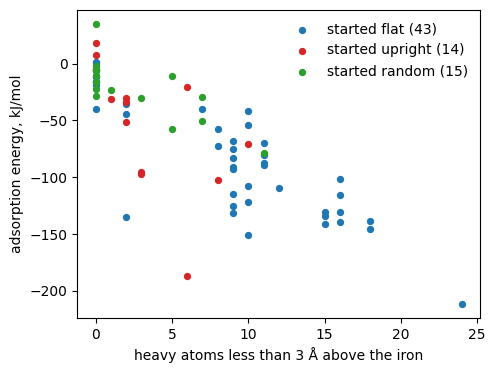

correlation of the adsorption energy with the count: -0.82


In [3]:
import matplotlib.pyplot as plt

def heavy_heights(mol):
    xyz = mol.GetConformer().GetPositions()
    return np.array([p[2] for p, a in zip(xyz, mol.GetAtoms()) if a.GetAtomicNum() > 1])

near = np.array([(heavy_heights(m) < 3.0).sum() for m in mols])
start = np.array([m.GetProp("pose_label") for m in mols])
fig, ax = plt.subplots(figsize=(5.2, 4.0))
for label, colour in (("flat", "C0"), ("upright", "C3"), ("random", "C2")):
    sel = start == label
    ax.scatter(near[sel], y[sel], s=18, color=colour, label="started %s (%d)" % (label, sel.sum()))
ax.set_xlabel("heavy atoms less than 3 Å above the iron")
ax.set_ylabel("adsorption energy, kJ/mol")
ax.legend(frameon=False); plt.show()
print("correlation of the adsorption energy with the count: %.2f" % np.corrcoef(y, near)[0, 1])

## A look at one adsorbate

The molecule with the strongest adsorption, on a patch of the surface. The file holds the
molecules alone, so the iron atoms are built here by `bcc110_slab`, which makes the slab the
poses were relaxed on. Only its top two layers are drawn.

In [4]:
from cmfqsar.slab import bcc110_slab

fs = FieldSet.create(alpha=1.0)
mf = [build_fields(m, fs, n) for m, n in zip(mols, names)]

def view_on_surface(m, radius=8.0, size=(620, 420)):
    """The molecule on the iron atoms of the top two layers that lie under it."""
    try:
        import py3Dmol
    except ImportError:
        print("py3Dmol is not installed (pip install py3Dmol); the 3D view is skipped")
        return None
    slab = bcc110_slab()
    iron = slab.positions[slab.positions[:, 2] > -2.5]
    lengths = np.array([slab.cell[0, 0], slab.cell[1, 1]])
    centre = np.asarray(m.coords, float)[:, :2].mean(axis=0)
    shift = iron[:, :2] - centre
    shift -= lengths * np.round(shift / lengths)          # the periodic image under the molecule
    iron = np.column_stack([centre + shift, iron[:, 2]])
    iron = iron[np.linalg.norm(shift, axis=1) < radius]
    xyz = "%d\n\n" % len(iron) + "\n".join("Fe %.3f %.3f %.3f" % tuple(p) for p in iron)
    v = py3Dmol.view(width=size[0], height=size[1])
    v.addModel(xyz, "xyz")
    v.setStyle({"model": 0}, {"sphere": {"scale": 0.9, "color": "#b9783a"}})
    v.addModel(m.molblock, "mol")
    v.setStyle({"model": 1}, {"stick": {"radius": 0.14}, "sphere": {"scale": 0.25}})
    v.zoomTo(); v.rotate(-70, "x")
    return v.show()

strongest = int(np.argmin(y))
print(names[strongest], ": %.0f kJ/mol, %d heavy atoms near the iron" % (y[strongest], near[strongest]))
view_on_surface(mf[strongest])

2,6-Bis(1H-benzimidazol-2-yl)pyridine : -212 kJ/mol, 24 heavy atoms near the iron


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

## The surface kernel

`kernel_source="surface"` describes a molecule by the distribution of its field weights over the
**in-plane** distance between two atoms, resolved by the heights of both atoms. Two poses that
differ by a shift in the plane, or by a turn about the normal, have the same description. Two
poses that differ in height or in tilt do not. The channels run over in-plane distances up to
12 Å and over heights from 1 to 6 Å above the surface.

The fields are the five default ones. Only the ridge *lambda* is chosen here.

In [5]:
from cmfqsar import CMFModel
from cmfqsar.model import grid_search

table = AtomTable.from_molecules(mf)
LAMS = [1e-4, 1e-3, 1e-2, 0.1, 1.0, 10.0]
model = CMFModel(fieldset=fs, method="krr", normalize=True, kernel_source="surface")
grid_search(table, y, model, alphas=[1.0], lams=LAMS)
model.fit(table, y, cv_folds=10)
print(model.stats.summary())

Training set: n = 72
  r2 (fit)        = 0.974    RMSE (fit)  = 8.561
  q2 (10-fold CV)  = 0.674    RMSEcv      = 30.383


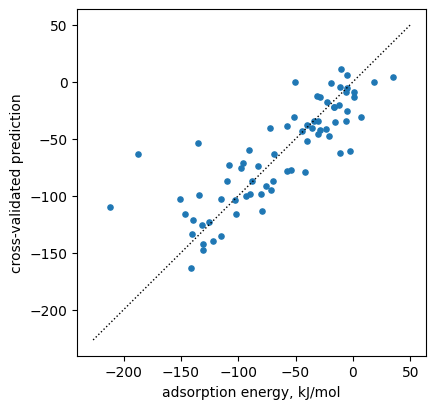

In [6]:
y_cv = model.stats.extra["y_cv"]
fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.scatter(y, y_cv, s=14)
lo, hi = y.min() - 15, y.max() + 15
ax.plot([lo, hi], [lo, hi], "k:", lw=1)
ax.set_xlabel("adsorption energy, kJ/mol"); ax.set_ylabel("cross-validated prediction"); plt.show()

## Three kernels and one count

The same poses under the kernels of the first two notebooks. The overlap kernel needs a frame, and
here it gets the frame of the surface as the relaxation left it, which fixes the height and
leaves the place in the plane to chance. The rotation-invariant kernel needs no frame at all, and
it pays for that with the height.

The fourth bar is the count of the first plot, in a linear regression with one coefficient. All
four are scored on the same ten folds, five times over.

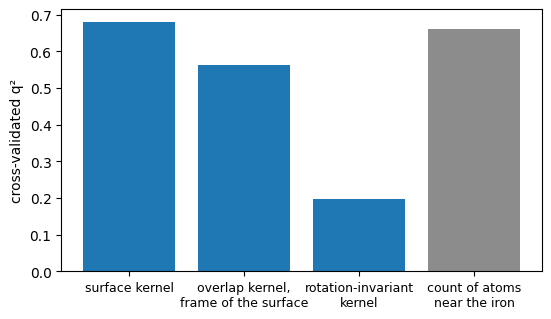

surface kernel                           q2 = 0.68
overlap kernel, frame of the surface     q2 = 0.56
rotation-invariant kernel                q2 = 0.20
count of atoms near the iron             q2 = 0.66
the count with a limit of 2.0 Å: q2 = 0.69
the count with a limit of 2.5 Å: q2 = 0.68
the count with a limit of 3.5 Å: q2 = 0.63
the count with a limit of 4.0 Å: q2 = 0.63


In [7]:
def q2_of_model(kind, alphas, seeds=range(5)):
    m = CMFModel(fieldset=fs, method="krr", normalize=True, kernel_source=kind)
    grid_search(table, y, m, alphas=alphas, lams=LAMS)
    scores = []
    for seed in seeds:
        m.fit(table, y, cv_folds=10, cv_seed=seed)
        scores.append(m.stats.q2)
    return float(np.mean(scores))

def q2_of_count(count, seeds=range(5)):
    X = np.column_stack([np.ones(len(y)), count])
    scores = []
    for seed in seeds:
        pred = np.zeros(len(y))
        for test in np.array_split(np.random.default_rng(seed).permutation(len(y)), 10):
            fit = np.setdiff1d(np.arange(len(y)), test)
            coef = np.linalg.lstsq(X[fit], y[fit], rcond=None)[0]
            pred[test] = X[test] @ coef
        scores.append(1 - np.sum((pred - y) ** 2) / np.sum((y - y.mean()) ** 2))
    return float(np.mean(scores))

scores = {
    "surface kernel": q2_of_model("surface", [1.0]),
    "overlap kernel,\nframe of the surface": q2_of_model("fields", [0.3, 0.5, 0.8, 1.2, 2.0]),
    "rotation-invariant\nkernel": q2_of_model("autocorrelation", [1.0]),
    "count of atoms\nnear the iron": q2_of_count(near),
}
fig, ax = plt.subplots(figsize=(6.2, 3.4))
ax.bar(range(len(scores)), list(scores.values()), color=["C0", "C0", "C0", "0.55"])
ax.set_xticks(range(len(scores))); ax.set_xticklabels(list(scores), fontsize=9)
ax.set_ylabel("cross-validated q²"); plt.show()
for name, value in scores.items():
    print("%-40s q2 = %.2f" % (name.replace("\n", " "), value))
for cut in (2.0, 2.5, 3.5, 4.0):
    count = np.array([(heavy_heights(m) < cut).sum() for m in mols])
    print("the count with a limit of %.1f Å: q2 = %.2f" % (cut, q2_of_count(count)))

Read the four numbers in two steps.

**Among the kernels the order is the one the physics asks for.** The surface kernel is ahead of
the overlap kernel, which is given a place in the plane that means nothing, and far ahead of the
rotation-invariant kernel, which cannot see the height.

**The count does as well as the surface kernel.** One number, the atoms that lie on the metal,
predicts these adsorption energies as well as several thousand channels do, and the limit of
3 Å was not tuned: the lines above show the same result from 2 to 4 Å. So on this set the kernel
has found what decides the energy, and it found it without being told, but it has not found more
than that. This is the comparison to make before a field model of a new set of poses is given
credit: count first, then ask what the fields add.

The scores of this cell choose the ridge on the same folds they are scored on. The manual gives
the numbers from a nested cross-validation, which are a little lower and in the same order.

## The invariance, tested

The claim about the plane can be checked directly. Every pose is turned by a random angle about
the normal and moved by up to 6 Å in the plane, and both models predict again. Then every
molecule is lifted by 1 Å, which is a change the surface kernel must see.

In [8]:
from rdkit import Chem

def moved(mol, rng, lift=0.0, in_plane=True):
    out = Chem.Mol(mol)
    xyz = np.array(out.GetConformer().GetPositions())
    if in_plane:
        t = rng.uniform(0, 2 * np.pi)
        turn = np.array([[np.cos(t), -np.sin(t), 0], [np.sin(t), np.cos(t), 0], [0, 0, 1.0]])
        centre = xyz.mean(axis=0)
        xyz = (xyz - centre) @ turn.T + centre + [rng.uniform(-6, 6), rng.uniform(-6, 6), 0.0]
    xyz[:, 2] += lift
    conf = out.GetConformer()
    for i, p in enumerate(xyz):
        conf.SetAtomPosition(i, [float(v) for v in p])
    return out

def table_of(some):
    return AtomTable.from_molecules([build_fields(m, fs, n) for m, n in zip(some, names)])

overlap = CMFModel(fieldset=fs, method="krr", normalize=True, params={"lam": 1.0})
overlap.fit(table, y, cv_folds=0)
rng = np.random.default_rng(0)
in_plane = table_of([moved(m, rng) for m in mols])
print("after a move in the plane, the largest change of a prediction:")
print("  surface kernel  %.1e kJ/mol" % np.abs(model.predict(in_plane) - model.predict(table)).max())
print("  overlap kernel  %.0f kJ/mol" % np.abs(overlap.predict(in_plane) - overlap.predict(table)).max())
lifted = table_of([moved(m, rng, lift=1.0, in_plane=False) for m in mols])
change = model.predict(lifted) - model.predict(table)
print("after a lift of 1 Å the surface kernel predicts %.0f kJ/mol weaker adsorption on average" % change.mean())

after a move in the plane, the largest change of a prediction:


  surface kernel  2.3e-13 kJ/mol


  overlap kernel  82 kJ/mol


after a lift of 1 Å the surface kernel predicts 21 kJ/mol weaker adsorption on average


## Reading the model: the co-pattern

An invariant kernel has no co-field, because it does not know where anything is in the plane.
What it has is the **co-pattern**: one weight for every channel. `copattern` returns it as a
curve over the in-plane distance for one pair of field types, summed over the heights. The value
drawn is the weight times the spread of the channel over the molecules, which is how much the
channel moves a prediction. A negative value means a stronger adsorption.

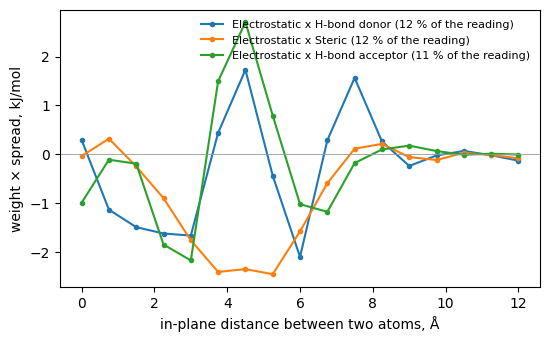

In [9]:
from cmfqsar.copattern import copattern, pair_labels

pairs = pair_labels(model, fs)
curves = [copattern(model, fs, k, "weight x spread") for k in range(len(pairs))]
size = np.array([np.abs(c.moved).sum() for c in curves])
fig, ax = plt.subplots(figsize=(6.2, 3.6))
for k in np.argsort(-size)[:3]:
    ax.plot(curves[k].x, curves[k].y, marker="o", ms=3,
            label="%s (%.0f %% of the reading)" % (pairs[k], 100 * size[k] / size.sum()))
ax.axhline(0, color="0.6", lw=0.6)
ax.set_xlabel("in-plane distance between two atoms, Å")
ax.set_ylabel("weight × spread, kJ/mol")
ax.legend(frameon=False, fontsize=8); plt.show()

The single channels behind the curves carry the two heights as well. `top_channels` ranks them.
Each line names the pair of fields, the in-plane distance and the heights of the two atoms.

In [10]:
from cmfqsar.invariant import SurfaceSpec, surface_channel_labels
from cmfqsar.periodic import top_channels

labels = surface_channel_labels(fs, SurfaceSpec())      # the default channels, as the model uses
print("%-62s %8s %8s" % ("channel", "weight", "spread"))
for label, weight, spread in top_channels(model, labels, n=8):
    print("%-62s %8.2f %8.3f" % (label, weight, spread))

channel                                                          weight   spread
H-bond donor @ rho 0.00 A, z 5.0 / 5.0 A                          19.95    0.042
Electrostatic x Steric @ rho 3.75 A, z 3.0 / 3.0 A               -30.68    0.020
Electrostatic x Steric @ rho 3.00 A, z 3.0 / 3.0 A               -26.76    0.022
H-bond acceptor x H-bond donor @ rho 3.00 A, z 6.0 / 6.0 A        14.72    0.037
Electrostatic x H-bond donor @ rho 6.00 A, z 3.0 / 3.0 A         -17.06    0.028
H-bond acceptor x H-bond donor @ rho 2.25 A, z 6.0 / 6.0 A        17.30    0.028
H-bond donor @ rho 0.00 A, z 4.0 / 5.0 A                          16.86    0.027
H-bond donor @ rho 0.00 A, z 5.0 / 4.0 A                          16.86    0.027


A weight is added to the predicted energy, so a negative weight is a stronger adsorption. Read two
kinds of line. The electrostatic field with the steric field at a height of 3 Å has a negative
weight: charge and bulk that both lie on the metal go with a stronger adsorption. The
hydrogen-bond donor at heights of 4 to 6 Å has a positive weight: a molecule that holds its N-H
far above the metal adsorbs more weakly. Both lines say how much of the molecule is at which
height, which is the count of the first plot in more detail.

The co-pattern says which pair of fields, which distance and which heights carry the signal. It
cannot say where on the molecule they are. For that question the manual has the frame of the
surface by rule, in *Posed by rule: the surface frame without the slab*.

## Molecules the model has not seen

A quarter of the molecules are set aside, the model is fitted on the rest with the ridge chosen
above, and the adsorption energies of the quarter are predicted. With 18 molecules the result
depends on which ones are drawn, so three draws are shown.

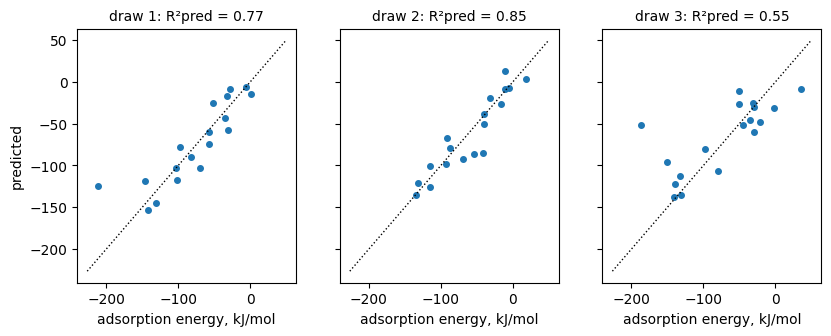

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(9.6, 3.3), sharex=True, sharey=True)
for ax, seed in zip(axes, range(3)):
    order = np.random.default_rng(seed).permutation(len(y))
    test, fit = order[:18], order[18:]
    part = CMFModel(fieldset=fs, method="krr", normalize=True, kernel_source="surface",
                    params={"lam": model.params["lam"]})
    part.fit(AtomTable.from_molecules([mf[i] for i in fit]), y[fit], cv_folds=0)
    pred = part.predict(AtomTable.from_molecules([mf[i] for i in test]))
    r2 = 1 - np.sum((pred - y[test]) ** 2) / np.sum((y[test] - y[fit].mean()) ** 2)
    ax.scatter(y[test], pred, s=16)
    ax.plot([lo, hi], [lo, hi], "k:", lw=1)
    ax.set_title("draw %d: R²pred = %.2f" % (seed + 1, r2), fontsize=10)
    ax.set_xlabel("adsorption energy, kJ/mol")
axes[0].set_ylabel("predicted"); plt.show()

## The same model from the command line, and the surface in the window

```
cmf build examples/corrosion_fe110/157_benzimidazole_uma.sdf --activity E_ads_kJmol --kernel surface --save fe110.cmf
cmf predict fe110.cmf new_poses.sdf
```

New poses have to be in the same frame as these: the normal along z and the top layer of the
metal at z = 0. Nothing checks that convention.

The application shows a slab with its adsorbate in the window for crystals: open
`examples/corrosion_fe110/benzimidazole_on_fe110.extxyz` there with *Periodic in* set to
*ab: a layer*.

Where to read further: *Molecules on a surface: the in-plane invariant kernel* for the kernel and
its nested scores, *The co-pattern as a chart* for what a co-pattern may be read for, and *A metal
surface as the receptor* for what the slab itself offers a model, which for a clean metal is its
shape and little else.